# Phase D — Forecasting

**Project:** PM Accelerator AI Engineer Intern assessment  
**Input:** `data/processed/weather_daily_global_core.csv` from Phase B  
**Target:** equal-weighted daily mean temperature across the 183 core locations (`temperature_celsius`)  
**Forecast horizon:** 30 days in each backtest fold, plus a 14-day post-sample projection  
**Evaluation:** six chronological rolling-origin folds, 180 test predictions per model

This notebook compares two naive baselines with two real forecasting models. It
uses only information available before each test window for fitting and feature
construction. Results are reported in **°C** and **percent**; no result is
claimed unless the code below produced it.


## 1. Target and chronological evaluation design

The target is the **equal-weighted daily mean temperature of the 183 core
locations** in the cleaned panel. It is a panel average, not an area- or
population-weighted global temperature. The source table has 879 dates with at
least one row; reindexing to a complete daily calendar gives 881 dates. Of
these, 875 have `coverage_ok == True` (at least 150 cities). The other six dates
are either low-coverage or absent from the table.

Those six dates are **not evaluation targets**. They are forward-filled only so
that the recursive models receive a continuous daily input series; all six occur
before the first test window. The forecast evaluation uses six non-overlapping
30-day windows from **2026-04-17 through 2026-10-13**. In every fold the training
set ends one day before the test window starts.

The models are:

| Model | Role | Specification |
|---|---|---|
| Persistence | baseline | Repeat the last training value for every horizon. |
| Seasonal naive | baseline | Use the value from the same calendar day 365 days earlier. |
| Ridge + Fourier | real model | Ridge regression on annual Fourier terms, lags, and rolling means; recursive 30-day forecast. Scaling is fitted inside each training fold. |
| SARIMAX + Fourier | real model | SARIMAX `(1, 0, 1)` with annual Fourier exogenous terms and a constant; direct 30-day forecast. |


In [1]:
import sys
import time
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import REPORT_DIR
from src.eda import save_figure, set_plot_style
from src.forecasting import (
    FEATURE_COLUMNS,
    build_feature_frame,
    fit_ridge,
    forecast_ridge,
    future_dates,
    horizon_metrics,
    load_global_series,
    make_folds,
    per_fold_metrics,
    run_backtest,
    summarize_metrics,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
set_plot_style()
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

MODEL_LABELS = {
    "persistence": "Persistence",
    "seasonal_naive": "Seasonal naive",
    "ridge_fourier": "Ridge + Fourier",
    "sarimax_fourier": "SARIMAX + Fourier",
}
MODEL_COLORS = {
    "persistence": "#6C757D",
    "seasonal_naive": "#B44C5E",
    "ridge_fourier": "#2A6F97",
    "sarimax_fourier": "#E9A23B",
}
MODEL_ORDER = ["persistence", "seasonal_naive", "sarimax_fourier", "ridge_fourier"]

frame = load_global_series()
folds = make_folds(frame)

observed = frame.loc[frame["observed"], "target"]
non_observed = frame.loc[
    ~frame["observed"],
    ["temperature_celsius", "coverage_ok", "n_cities", "target"],
].copy()
non_observed.index.name = "date_utc"

fold_rows = []
for fold_number, (train_index, test_index) in enumerate(folds, start=1):
    fold_rows.append(
        {
            "fold": fold_number,
            "train_start": train_index.min().date(),
            "train_end": train_index.max().date(),
            "train_days": len(train_index),
            "test_start": test_index.min().date(),
            "test_end": test_index.max().date(),
            "test_days": len(test_index),
            "test_observed": int(frame.loc[test_index, "observed"].sum()),
        }
    )
fold_table = pd.DataFrame(fold_rows)

print(f"Daily calendar rows: {len(frame):,}")
print(f"Observed target values: {len(observed):,} of {len(frame):,}")
print(f"Target range (observed): {observed.min():.2f} to {observed.max():.2f} °C")
print(f"Non-observed dates forward-filled: {len(non_observed)}")
print()
display(non_observed.round(3))
print()
display(fold_table)


Daily calendar rows: 881
Observed target values: 875 of 881
Target range (observed): 13.51 to 27.80 °C
Non-observed dates forward-filled: 6



,temperature_celsius,coverage_ok,n_cities,target
date_utc,,,,
2024-07-13,26.733,False,126.0,27.318
2024-07-21,7.100,False,1.0,27.477
2024-07-22,NaN,NaN,NaN,27.477
2026-01-19,NaN,NaN,NaN,14.205
2026-03-08,16.294,False,108.0,16.861
2026-03-09,17.154,False,90.0,16.861


,fold,train_start,train_end,train_days,test_start,test_end,test_days,test_observed
0,1,2024-05-16,2026-04-16,701,2026-04-17,2026-05-16,30,30
1,2,2024-05-16,2026-05-16,731,2026-05-17,2026-06-15,30,30
2,3,2024-05-16,2026-06-15,761,2026-06-16,2026-07-15,30,30
3,4,2024-05-16,2026-07-15,791,2026-07-16,2026-08-14,30,30
4,5,2024-05-16,2026-08-14,821,2026-08-15,2026-09-13,30,30
5,6,2024-05-16,2026-09-13,851,2026-09-14,2026-10-13,30,30


The table above makes the split auditable: every test window has 30
observed target values, and the training window ends on the day before the
test window begins. The six forward-filled dates are in 2024 or early 2026 and
do not enter any test window.

The next figure shows the target series and the six test windows, so the
chronology is visible rather than only described.


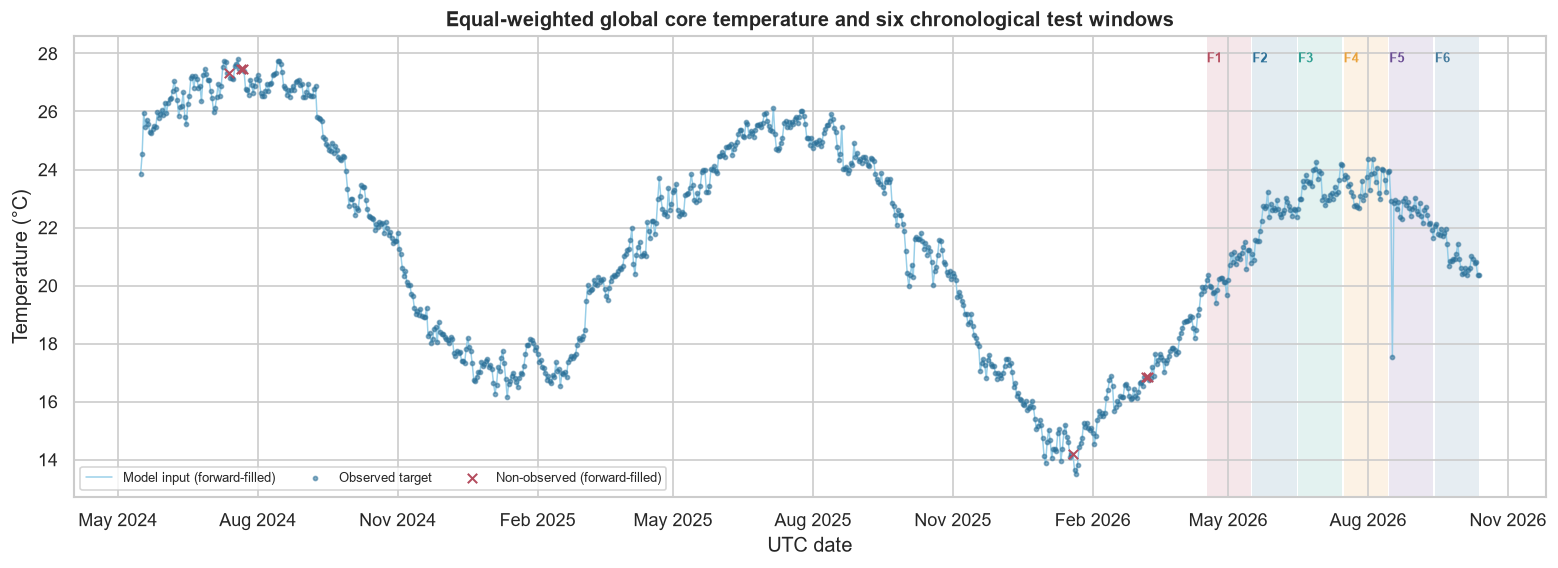

fig_12_forecast_windows.png


In [2]:
fig, ax = plt.subplots(figsize=(13.2, 4.9))

ax.plot(
    frame.index,
    frame["target"],
    color="#8ECAE6",
    linewidth=0.9,
    alpha=0.9,
    label="Model input (forward-filled)",
)
ax.scatter(
    frame.loc[frame["observed"]].index,
    frame.loc[frame["observed"], "target"],
    color="#2A6F97",
    s=6,
    alpha=0.55,
    label="Observed target",
    zorder=3,
)
ax.scatter(
    frame.loc[~frame["observed"]].index,
    frame.loc[~frame["observed"], "target"],
    color="#B44C5E",
    marker="x",
    s=32,
    linewidths=1.2,
    label="Non-observed (forward-filled)",
    zorder=4,
)

window_colors = ["#B44C5E", "#2A6F97", "#2A9D8F", "#E9A23B", "#6A4C93", "#457B9D"]
for fold_number, (_, test_index) in enumerate(folds, start=1):
    ax.axvspan(
        test_index.min(),
        test_index.max(),
        color=window_colors[fold_number - 1],
        alpha=0.13,
        linewidth=0,
        zorder=0,
    )
    ax.text(
        test_index.min(),
        0.965,
        f"F{fold_number}",
        transform=ax.get_xaxis_transform(),
        ha="left",
        va="top",
        fontsize=8,
        color=window_colors[fold_number - 1],
        fontweight="bold",
    )

ax.set_xlabel("UTC date")
ax.set_ylabel("Temperature (°C)")
ax.set_title(
    "Equal-weighted global core temperature and six chronological test windows"
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(frame["target"].min() - 0.8, frame["target"].max() + 0.8)
ax.legend(loc="lower left", ncol=3, fontsize=8, frameon=True)
fig.tight_layout()
path = save_figure(fig, "fig_12_forecast_windows.png")
plt.show()
print(path.name)


### Data-quality diagnostic before modelling

The long series shows one conspicuous one-day dip in August 2026. The raw
city-level readings behind it are not plausible as a true global change: many
northern stations fall by roughly 20–30 °C while several southern stations rise
by a similar amount on the same UTC date. That pattern is consistent with a
source-data or timestamp event, not a physical one-day global temperature
change. The value is **retained** in the backtest and flagged in the summary
rather than removed after seeing model scores; fold 5 therefore contains this
shock.


In [3]:
observed_series = frame.loc[frame["observed"], "target"].copy()
daily_change = observed_series.diff()
largest_change_date = daily_change.abs().idxmax()
largest_change_value = float(daily_change.loc[largest_change_date])
largest_change_abs = daily_change.abs().sort_values(ascending=False).head(6)
largest_changes = pd.DataFrame(
    {
        "date_utc": largest_change_abs.index.strftime("%Y-%m-%d"),
        "previous_c": observed_series.shift(1).loc[largest_change_abs.index].to_numpy(),
        "current_c": observed_series.loc[largest_change_abs.index].to_numpy(),
        "change_c": daily_change.loc[largest_change_abs.index].to_numpy(),
    }
)
print(
    f"Largest absolute observed one-day change: {daily_change.abs().max():.2f} °C "
    f"on {daily_change.abs().idxmax():%Y-%m-%d}"
)
display(largest_changes.round(3))


Largest absolute observed one-day change: 5.36 °C on 2026-08-17


,date_utc,previous_c,current_c,change_c
0,2026-08-17,22.907,17.543,-5.363
1,2026-08-18,17.543,22.853,5.310
2,2025-08-21,25.470,24.031,-1.439
3,2024-05-18,24.528,25.958,1.430
4,2025-10-07,20.302,21.609,1.308
5,2025-04-05,21.974,20.757,-1.216


## 2. Model details and leakage controls

**Persistence** repeats the last training value for all 30 days. **Seasonal
naive** uses the observed value from the same calendar day one year earlier.
Both are fixed rules, not fitted models.

**Ridge + Fourier** uses 15 inputs: three annual sine/cosine pairs, lags at 1,
2, 3, 7, 14, 30, and 365 days, plus 7-day and 30-day rolling means shifted by
one day. The rolling means and lags never include the current target. A
`StandardScaler` and `Ridge(alpha=1.0)` are fitted inside each training fold.
The 30-day forecast is recursive: each predicted day becomes part of the
history for the next day's lag and rolling-mean features.

**SARIMAX + Fourier** uses the same annual Fourier terms as exogenous regressors
and a `(1, 0, 1)` autoregressive moving-average structure with a constant. It is
fitted separately on each training fold and forecasts the 30-day test window
directly. BFGS was used because the default optimiser did not fully converge in
one development fold; all six final fits converged without a warning.

No test-period target, scaler statistic, feature value, or hyperparameter is
used to fit a model. The next cell checks the first fold explicitly.


In [4]:
train_index, test_index = folds[0]
train = frame.loc[train_index].copy()
test = frame.loc[test_index].copy()

assert train.index.max() < test.index.min(), "Training must precede testing."
assert len(train.index.intersection(test.index)) == 0, "Train/test overlap found."
assert bool(frame.loc[test_index, "observed"].all()), "Test window contains a missing target."

feature_frame = build_feature_frame(train["target"])
usable = feature_frame.loc[train.index, FEATURE_COLUMNS].dropna()
sample_date = usable.index[-1]
previous_date = sample_date - pd.Timedelta(days=1)

manual_lag_1 = float(train.loc[previous_date, "target"])
manual_rolling_7 = float(train.loc[:previous_date, "target"].tail(7).mean())
ridge_check = fit_ridge(train)
scaler = ridge_check.named_steps["scaler"]
scaler_rows = int(np.asarray(scaler.n_samples_seen_).max())

leakage_checks = pd.DataFrame(
    [
        ("Training end before test start", str(train.index.max().date() < test_index.min().date())),
        ("Train/test date overlap", str(len(train.index.intersection(test_index)))),
        ("Test targets observed", f"{int(frame.loc[test_index, 'observed'].sum())}/{len(test_index)}"),
        ("Complete feature rows used to fit", f"{len(usable):,}"),
        ("Scaler rows", f"{scaler_rows:,}"),
        ("Scaler fit includes test rows", str(any(test_index.isin(usable.index)))),
        ("Feature input count", f"{len(FEATURE_COLUMNS)}"),
        (
            "lag_1 matches prior target",
            str(np.isclose(feature_frame.loc[sample_date, "lag_1"], manual_lag_1)),
        ),
        (
            "rolling_mean_7 matches prior 7 days",
            str(np.isclose(feature_frame.loc[sample_date, "rolling_mean_7"], manual_rolling_7)),
        ),
    ],
    columns=["Check", "Result"],
)

print(
    f"Fold 1: train {train.index.min().date()} to {train.index.max().date()} "
    f"({len(train):,} days); test {test_index.min().date()} to "
    f"{test_index.max().date()} ({len(test):,} days)"
)
display(leakage_checks)


Fold 1: train 2024-05-16 to 2026-04-16 (701 days); test 2026-04-17 to 2026-05-16 (30 days)


,Check,Result
0,Training end before test start,True
1,Train/test date overlap,0
2,Test targets observed,30/30
3,Complete feature rows used to fit,336
4,Scaler rows,336
5,Scaler fit includes test rows,False
6,Feature input count,15
7,lag_1 matches prior target,True
8,rolling_mean_7 matches prior 7 days,True


## 3. Rolling-origin backtest

Each model is refitted at every origin. The backtest therefore evaluates 30-day
forecasts from six different historical starting points, not one long
in-sample prediction. Predictions are stored in long form for aggregate,
per-fold, and per-horizon metrics.


In [5]:
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    predictions, folds = run_backtest(frame)
elapsed = time.perf_counter() - t0

if caught:
    print("Warnings captured during backtest:")
    for warning in caught:
        print(f"- {type(warning.message).__name__}: {warning.message}")
    raise RuntimeError("Unexpected warnings during the forecasting backtest.")

print(f"Backtest runtime: {elapsed:.1f} seconds")
print(f"Prediction rows: {len(predictions):,}")
print(f"Folds: {predictions['fold'].nunique()} | Models: {predictions['model'].nunique()}")
print(f"Rows per model: {predictions.groupby('model').size().to_dict()}")
print("SARIMAX convergence: 6/6 folds (the fit raises if a fold does not converge).")
display(predictions.head(8))


Backtest runtime: 8.4 seconds
Prediction rows: 720
Folds: 6 | Models: 4
Rows per model: {'persistence': 180, 'ridge_fourier': 180, 'sarimax_fourier': 180, 'seasonal_naive': 180}
SARIMAX convergence: 6/6 folds (the fit raises if a fold does not converge).


,fold,origin,date,horizon,actual,model,prediction,observed
0,1,2026-04-16,2026-04-17,1,20.175275,persistence,19.934426,True
1,1,2026-04-16,2026-04-18,2,20.363736,persistence,19.934426,True
2,1,2026-04-16,2026-04-19,3,19.999454,persistence,19.934426,True
3,1,2026-04-16,2026-04-20,4,19.938251,persistence,19.934426,True
4,1,2026-04-16,2026-04-21,5,19.743716,persistence,19.934426,True
5,1,2026-04-16,2026-04-22,6,19.780328,persistence,19.934426,True
6,1,2026-04-16,2026-04-23,7,19.407650,persistence,19.934426,True
7,1,2026-04-16,2026-04-24,8,19.851099,persistence,19.934426,True


## 4. Aggregate accuracy

The primary metric is **MAE in °C** because it is easy to read in the target's
units. RMSE gives more weight to large misses; MAPE and sMAPE are reported in
percent. All four metrics are computed on the 180 out-of-sample predictions for
each model, pooled across the six folds.


In [6]:
summary = summarize_metrics(predictions)
summary["model_label"] = summary["model"].map(MODEL_LABELS)

display_table = summary[["model_label", "n", "mae", "rmse", "mape_pct", "smape_pct"]].copy()
display_table.columns = ["Model", "Predictions", "MAE (°C)", "RMSE (°C)", "MAPE (%)", "sMAPE (%)"]
display(display_table.round({"MAE (°C)": 3, "RMSE (°C)": 3, "MAPE (%)": 3, "sMAPE (%)": 3}))

best_row = summary.iloc[0]
best_model = str(best_row["model"])
best_label = MODEL_LABELS[best_model]
persistence_row = summary.loc[summary["model"].eq("persistence")].iloc[0]
improvement = 100.0 * (persistence_row["mae"] - best_row["mae"]) / persistence_row["mae"]

print(
    f"Lowest aggregate MAE: {best_label} — {best_row['mae']:.3f} °C "
    f"(RMSE {best_row['rmse']:.3f} °C; sMAPE {best_row['smape_pct']:.2f}%)"
)
print(
    f"Persistence MAE: {persistence_row['mae']:.3f} °C; "
    f"{best_label} is {improvement:.1f}% lower."
)
for row in summary.itertuples():
    delta = 100.0 * (persistence_row["mae"] - row.mae) / persistence_row["mae"]
    print(f"{MODEL_LABELS[row.model]:<18} MAE {row.mae:.3f} °C | vs persistence {delta:+.1f}%")


,Model,Predictions,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%)
0,Ridge + Fourier,180,0.501,0.746,2.303,2.251
1,SARIMAX + Fourier,180,0.958,1.194,4.354,4.210
2,Persistence,180,1.037,1.249,4.678,4.677
3,Seasonal naive,180,1.851,2.014,8.413,8.004


Lowest aggregate MAE: Ridge + Fourier — 0.501 °C (RMSE 0.746 °C; sMAPE 2.25%)
Persistence MAE: 1.037 °C; Ridge + Fourier is 51.7% lower.
Ridge + Fourier    MAE 0.501 °C | vs persistence +51.7%
SARIMAX + Fourier  MAE 0.958 °C | vs persistence +7.6%
Persistence        MAE 1.037 °C | vs persistence +0.0%
Seasonal naive     MAE 1.851 °C | vs persistence -78.6%


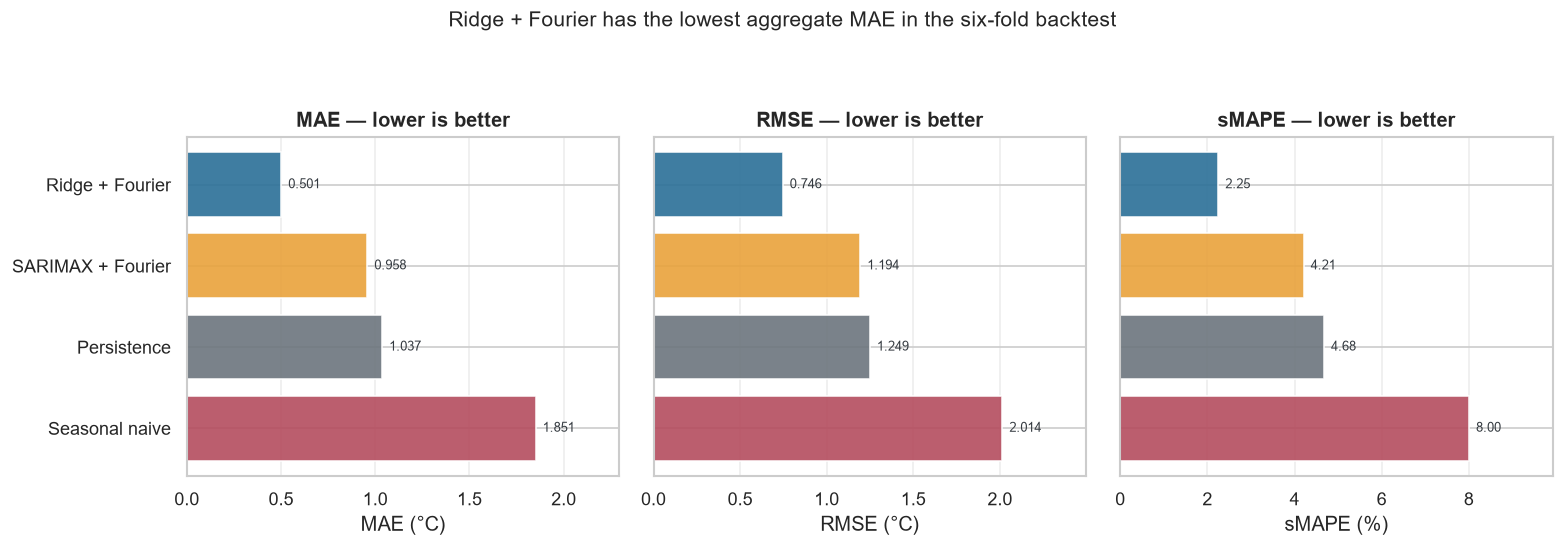

fig_13_forecast_model_metrics.png


In [7]:
ordered = summary.sort_values("mae").reset_index(drop=True)
labels = ordered["model"].map(MODEL_LABELS).tolist()
colors = ordered["model"].map(MODEL_COLORS).tolist()
y = np.arange(len(ordered))

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.5), sharey=True)
for ax, metric, title, fmt in [
    (axes[0], "mae", "MAE (°C)", ".3f"),
    (axes[1], "rmse", "RMSE (°C)", ".3f"),
    (axes[2], "smape_pct", "sMAPE (%)", ".2f"),
]:
    values = ordered[metric].to_numpy()
    ax.barh(y, values, color=colors, alpha=0.9)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel(title)
    ax.set_title(title.replace(" (°C)", "").replace(" (%)", "") + " — lower is better")
    for ypos, value in enumerate(values):
        ax.text(
            value + values.max() * 0.02,
            ypos,
            format(value, fmt),
            va="center",
            fontsize=8,
            color="#343A40",
        )
    ax.set_xlim(0, values.max() * 1.24)
    ax.grid(axis="x", alpha=0.35)

fig.suptitle(
    f"{best_label} has the lowest aggregate MAE in the six-fold backtest",
    fontsize=12.5,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_13_forecast_model_metrics.png")
plt.show()
print(path.name)


## 5. Error by fold and forecast horizon

Aggregate metrics can hide instability. The per-fold table shows whether a
model's advantage is consistent, and the horizon plot shows whether error grows
as the forecast extends. A model that only works at short horizons should not be
described as a reliable 30-day forecaster.


In [8]:
fold_metrics = per_fold_metrics(predictions)
fold_mae = (
    fold_metrics.pivot(index="fold", columns="model", values="mae")
    .rename(columns=MODEL_LABELS)
    .loc[:, [MODEL_LABELS[m] for m in MODEL_ORDER]]
)
print("Per-fold MAE (°C)")
display(fold_mae.round(3))

horizon = horizon_metrics(predictions)
horizon_mae = (
    horizon.pivot(index="horizon", columns="model", values="mae")
    .rename(columns=MODEL_LABELS)
    .loc[:, [MODEL_LABELS[m] for m in MODEL_ORDER]]
)
print("MAE (°C) at selected horizons")
display(horizon_mae.loc[[1, 7, 14, 21, 30]].round(3))


Per-fold MAE (°C)


model,Persistence,Seasonal naive,SARIMAX + Fourier,Ridge + Fourier
fold,,,,
1,0.655,2.335,1.269,0.624
2,1.609,1.868,0.665,0.570
3,1.066,1.940,0.793,0.496
4,0.717,1.930,1.328,0.570
5,1.463,1.904,1.349,0.449
6,0.711,1.131,0.345,0.298


MAE (°C) at selected horizons

model,Persistence,Seasonal naive,SARIMAX + Fourier,Ridge + Fourier
horizon,,,,
1,0.285,1.926,0.214,0.214
7,0.907,1.953,0.824,0.449
14,1.092,2.032,0.966,0.453
21,0.952,1.671,1.072,0.621
30,1.337,1.842,1.412,0.722


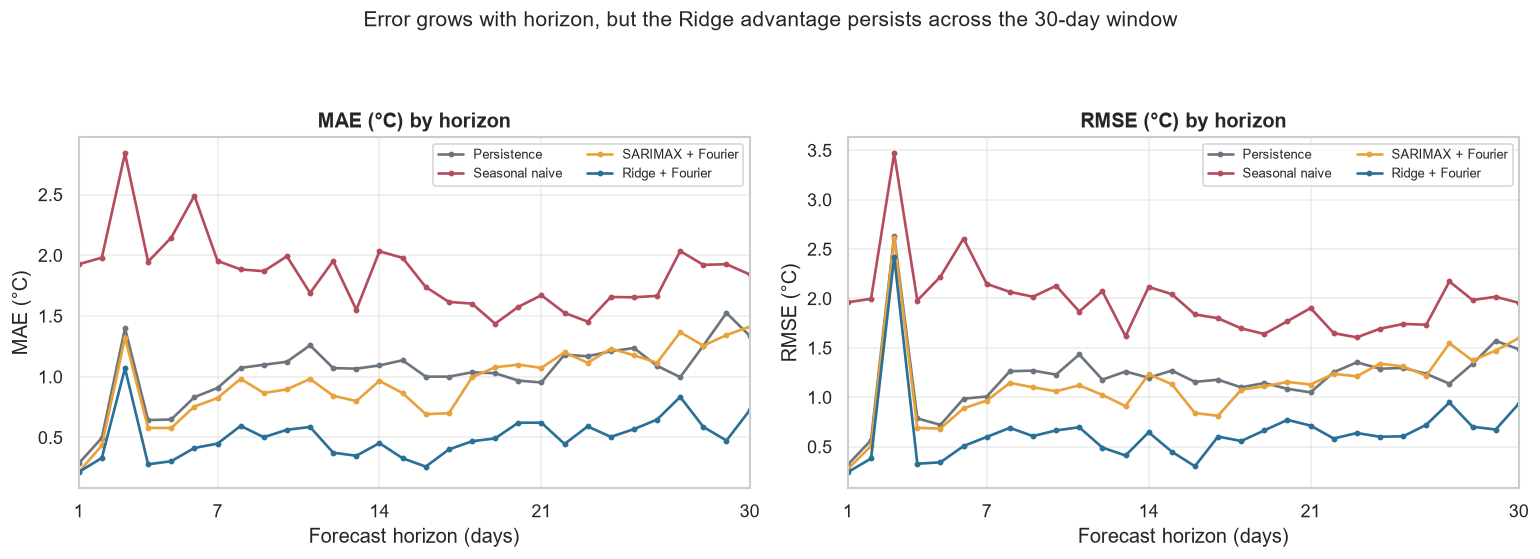

fig_14_forecast_error_by_horizon.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6), sharex=True)
for ax, metric, title in [
    (axes[0], "mae", "MAE (°C)"),
    (axes[1], "rmse", "RMSE (°C)"),
]:
    for model in MODEL_ORDER:
        subset = horizon.loc[horizon["model"].eq(model)].sort_values("horizon")
        ax.plot(
            subset["horizon"],
            subset[metric],
            color=MODEL_COLORS[model],
            linewidth=1.6,
            marker="o",
            markersize=2.5,
            label=MODEL_LABELS[model],
        )
    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel(title)
    ax.set_title(title + " by horizon")
    ax.set_xticks([1, 7, 14, 21, 30])
    ax.set_xlim(1, 30)
    ax.grid(alpha=0.35)
    ax.legend(fontsize=7.5, ncol=2, frameon=True)

fig.suptitle(
    "Error grows with horizon, but the Ridge advantage persists across the 30-day window",
    fontsize=12.5,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_14_forecast_error_by_horizon.png")
plt.show()
print(path.name)


## 6. Last holdout and post-sample projection

The last fold is the most recent 30-day window: **2026-09-14 to 2026-10-13**.
It is plotted separately because it is the closest approximation to a live
forecast in this dataset. The final projection then refits Ridge on all
available data and forecasts **2026-10-14 to 2026-10-27**.

The shaded band in the projection is an **empirical 80% band**, formed from the
10th and 90th percentiles of the pooled Ridge backtest residuals. It is not a
formal predictive distribution and it does not include uncertainty from missing
coverage or structural change.


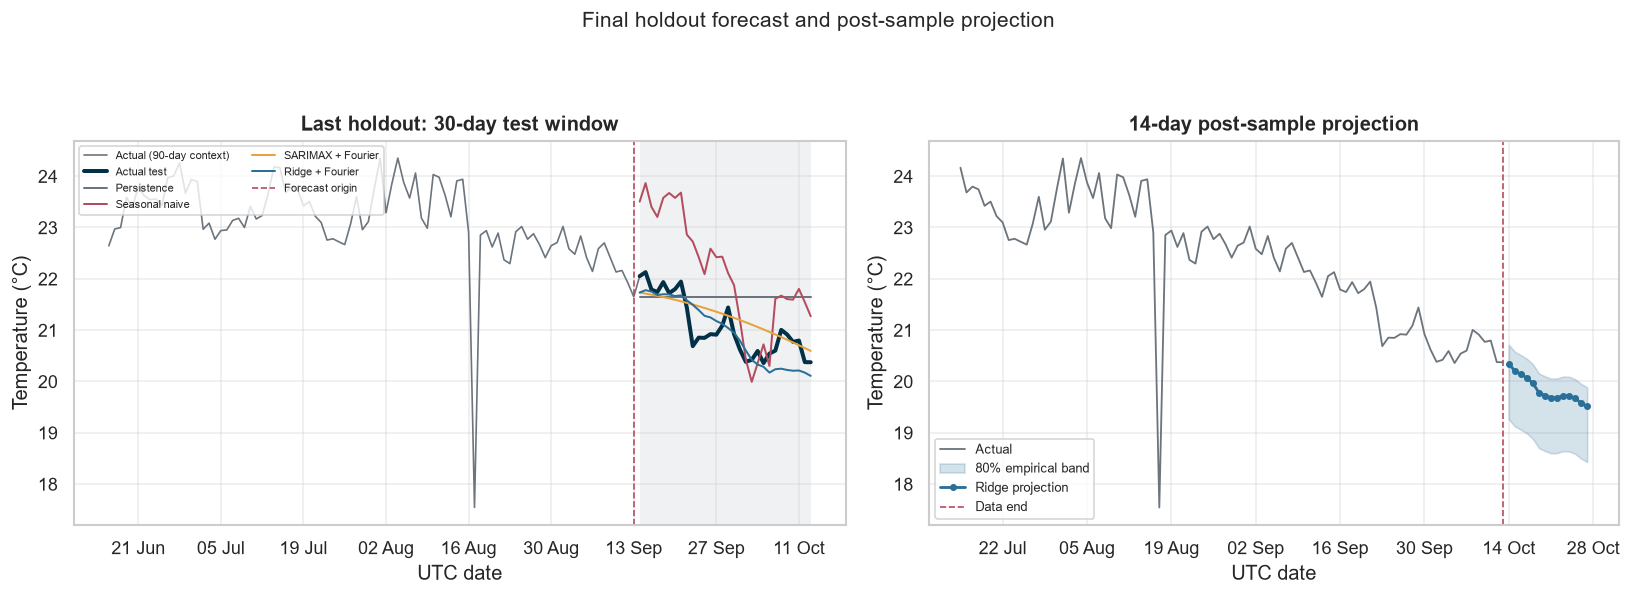

fig_15_holdout_and_projection.png
Last-fold metrics


,model_label,mae,rmse,mape_pct,smape_pct
0,Ridge + Fourier,0.298,0.370,1.419,1.424
1,SARIMAX + Fourier,0.345,0.410,1.653,1.638
2,Persistence,0.711,0.812,3.424,3.353
3,Seasonal naive,1.131,1.259,5.329,5.163


Projection: 2026-10-14 to 2026-10-27 | range 19.51 to 20.34 °C
Empirical 80% residual band: -1.08 to +0.37 °C around the Ridge point forecast


In [10]:
last_train_index, last_test_index = folds[-1]
last_test = frame.loc[last_test_index].copy()
origin = last_train_index.max()
last_predictions = (
    predictions.loc[predictions["fold"].eq(6)]
    .pivot(index="date", columns="model", values="prediction")
)
last_fold_metrics = (
    fold_metrics.loc[fold_metrics["fold"].eq(6)]
    .assign(model_label=lambda d: d["model"].map(MODEL_LABELS))
    .sort_values("mae")
)

final_ridge = fit_ridge(frame)
projection_dates = future_dates(frame.index.max(), 14)
projection = forecast_ridge(final_ridge, frame["target"].copy(), projection_dates)
ridge_residuals = predictions.loc[predictions["model"].eq("ridge_fourier")]
residual_values = (ridge_residuals["actual"] - ridge_residuals["prediction"]).to_numpy()
band_low, band_high = np.quantile(residual_values, [0.10, 0.90])
projection_low = projection + band_low
projection_high = projection + band_high

context_start = last_test_index.min() - pd.Timedelta(days=90)
context = frame.loc[context_start:last_test_index.max()]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.8, 4.9),
    gridspec_kw={"width_ratios": [1.12, 1.0]},
)

ax = axes[0]
ax.axvspan(
    last_test_index.min(),
    last_test_index.max(),
    color="#DEE2E6",
    alpha=0.45,
    linewidth=0,
    zorder=0,
)
ax.plot(
    context.index,
    context["target"],
    color="#6C757D",
    linewidth=1.0,
    label="Actual (90-day context)",
)
ax.plot(
    last_test_index,
    last_test["target"],
    color="#023047",
    linewidth=2.4,
    label="Actual test",
)
for model in MODEL_ORDER:
    ax.plot(
        last_predictions.index,
        last_predictions[model],
        color=MODEL_COLORS[model],
        linewidth=1.2,
        label=MODEL_LABELS[model],
    )
ax.axvline(origin, color="#B44C5E", linestyle="--", linewidth=1.0, label="Forecast origin")
ax.set_xlabel("UTC date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Last holdout: 30-day test window")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.grid(alpha=0.35)
ax.legend(fontsize=6.8, ncol=2, loc="upper left", frameon=True)

ax = axes[1]
recent_start = frame.index.max() - pd.Timedelta(days=90)
recent = frame.loc[recent_start:]
ax.plot(
    recent.index,
    recent["target"],
    color="#6C757D",
    linewidth=1.1,
    label="Actual",
)
ax.fill_between(
    projection.index,
    projection_low,
    projection_high,
    color="#2A6F97",
    alpha=0.20,
    label="80% empirical band",
)
ax.plot(
    projection.index,
    projection,
    color="#2A6F97",
    marker="o",
    markersize=3.2,
    linewidth=1.7,
    label="Ridge projection",
)
ax.axvline(frame.index.max(), color="#B44C5E", linestyle="--", linewidth=1.0, label="Data end")
ax.set_xlabel("UTC date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("14-day post-sample projection")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.grid(alpha=0.35)
ax.legend(fontsize=7.5, loc="lower left", frameon=True)

fig.suptitle("Final holdout forecast and post-sample projection", fontsize=12.5, y=1.01)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_15_holdout_and_projection.png")
plt.show()
print(path.name)

print("Last-fold metrics")
display(
    last_fold_metrics[["model_label", "mae", "rmse", "mape_pct", "smape_pct"]]
    .reset_index(drop=True)
    .round(3)
)
print(
    f"Projection: {projection.index.min().date()} to {projection.index.max().date()} | "
    f"range {projection.min():.2f} to {projection.max():.2f} °C"
)
print(
    f"Empirical 80% residual band: {band_low:+.2f} to {band_high:+.2f} °C "
    f"around the Ridge point forecast"
)


## 7. Forecast summary and limitations

The final cell writes `reports/forecast_summary.md` from the actual values
computed above. It records the target definition, fold design, metrics, last
holdout, projection, leakage controls, and caveats. The notebook does not claim
a long-term climate trend, a causal weather mechanism, or a live forecast beyond
the dataset end.


In [11]:
def markdown_table(dataframe: pd.DataFrame, digits: int = 3) -> str:
    columns = list(dataframe.columns)
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in dataframe.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                values.append(f"{value:.{digits}f}")
            else:
                values.append(str(value))
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


metrics_md = pd.DataFrame(
    {
        "Model": summary["model_label"],
        "Predictions": summary["n"],
        "MAE (°C)": summary["mae"],
        "RMSE (°C)": summary["rmse"],
        "MAPE (%)": summary["mape_pct"],
        "sMAPE (%)": summary["smape_pct"],
    }
)
fold_md = fold_table.copy()
fold_md["train_start"] = pd.to_datetime(fold_md["train_start"]).dt.strftime("%Y-%m-%d")
fold_md["train_end"] = pd.to_datetime(fold_md["train_end"]).dt.strftime("%Y-%m-%d")
fold_md["test_start"] = pd.to_datetime(fold_md["test_start"]).dt.strftime("%Y-%m-%d")
fold_md["test_end"] = pd.to_datetime(fold_md["test_end"]).dt.strftime("%Y-%m-%d")
fold_mae_md = fold_mae.reset_index()
fold_mae_md.columns = ["Fold"] + list(fold_mae_md.columns[1:])
horizon_mae_md = horizon_mae.loc[[1, 7, 14, 21, 30]].reset_index()
horizon_mae_md.columns = ["Horizon (days)"] + list(horizon_mae_md.columns[1:])
last_fold_md = last_fold_metrics[["model_label", "mae", "rmse", "mape_pct", "smape_pct"]].copy()
last_fold_md.columns = ["Model", "MAE (°C)", "RMSE (°C)", "MAPE (%)", "sMAPE (%)"]
fold_wins = int(fold_mae.idxmin(axis=1).eq(best_label).sum())

summary_text = f'''# Phase D — Forecast summary

**Status:** Complete for review. Phase D produced an executed forecasting
notebook, four forecast figures, and this summary. No Phase E or Phase F result
is included.

## Target and evaluation

- **Target:** equal-weighted daily mean temperature across the 183 core
  locations (`temperature_celsius`).
- **Calendar coverage:** {len(frame):,} daily dates from {frame.index.min():%Y-%m-%d}
  to {frame.index.max():%Y-%m-%d}; {len(observed):,} observed dates and
  {len(non_observed)} non-observed dates.
- **Evaluation:** {len(folds)} chronological rolling-origin folds, each with a
  30-day test window; {len(folds) * 30:,} predictions per model
  ({len(predictions):,} model-date predictions in total).
- **Test period:** {fold_table['test_start'].min()} through {fold_table['test_end'].max()}.
- **Training rule:** each training set ends one day before its test window.
- **Models:** persistence, seasonal naive, Ridge + Fourier, and SARIMAX +
  Fourier. Ridge scaling is fitted inside each training fold only.

{markdown_table(fold_md)}

## Aggregate metrics

{markdown_table(metrics_md)}

**Result:** `{best_label}` had the lowest aggregate MAE, **{best_row['mae']:.3f} °C**
(RMSE **{best_row['rmse']:.3f} °C**, MAPE **{best_row['mape_pct']:.3f}%**,
sMAPE **{best_row['smape_pct']:.3f}%**). Persistence had MAE
**{persistence_row['mae']:.3f} °C**, so the best model's MAE was
**{improvement:.1f}% lower** in this backtest. SARIMAX + Fourier had MAE
**{summary.loc[summary['model'].eq('sarimax_fourier'), 'mae'].iloc[0]:.3f} °C**.
`{best_label}` also had the lowest per-fold MAE in **{fold_wins} of
{len(folds)} folds**.

## Per-fold MAE

{markdown_table(fold_mae_md)}

## MAE at selected horizons

{markdown_table(horizon_mae_md)}

## Last holdout and 14-day projection

Last test fold: **{last_test_index.min():%Y-%m-%d} to {last_test_index.max():%Y-%m-%d}**.

{markdown_table(last_fold_md)}

The Ridge model was refit on all available data and projected
**{projection.index.min():%Y-%m-%d} to {projection.index.max():%Y-%m-%d}**.
The projected daily mean ranges from **{projection.min():.2f} °C** to
**{projection.max():.2f} °C**. The empirical 80% residual band is
**{band_low:+.2f} °C to {band_high:+.2f} °C** around the point forecast. This
band is descriptive, not a formal predictive distribution.

## Leakage controls

- The six test windows are chronological and non-overlapping; each training set
  ends one day before its test window.
- No test target is used in fitting. The first-fold check verifies zero
  train/test date overlap, 30/30 observed test targets, and scaler fitting on
  training rows only.
- Ridge lags and rolling means use only prior target values. During the
  recursive forecast, predictions become history; actual test values are not
  inserted.
- Fourier terms are deterministic calendar features and do not use the target.
- SARIMAX is fitted separately on each training fold. Its exogenous Fourier
  terms for the test window are known in advance.
- The six non-observed dates are forward-filled only for model continuity and
  are not evaluation targets. All six are before the first test window.

## Caveats

- The target is an equal-weighted average of 183 core locations, not a
  population- or area-weighted global temperature.
- The record spans a little over two years. It can describe seasonal behaviour
  in this panel but cannot establish a long-term climate trend.
- Coverage is uneven and readings are point-in-time values from different local
  times. The model treats the panel average as a single series and does not
  propagate coverage uncertainty.
- The largest observed one-day change is **{largest_change_value:+.2f} °C** on
  **{largest_change_date:%Y-%m-%d}**. The underlying city readings are broad and
  physically implausible as a one-day global event; it is likely a source-data
  or timestamp artefact. It is retained in fold 5 rather than removed after
  seeing model scores, so it contributes to fold-5 errors rather than being
  hidden.
- Six folds provide {len(folds) * 30:,} out-of-sample predictions per model
  ({len(predictions):,} total), but model selection used the same six folds. The
  reported score is therefore a model-selection estimate, not an untouched final
  holdout.
- Seasonal naive is a deliberately simple calendar benchmark; its poor result
  shows that last year's same-day value is not a good predictor of this series.
- The 14-day projection is post-sample and has not been evaluated against
  future observations. The empirical band is based on pooled backtest residuals
  and does not include structural-change uncertainty.
- Air quality, climate-region analysis, anomaly detection, and advanced
  feature-importance work belong to later phases and are not claimed here.

## Figures

- `reports/figures/fig_12_forecast_windows.png`
- `reports/figures/fig_13_forecast_model_metrics.png`
- `reports/figures/fig_14_forecast_error_by_horizon.png`
- `reports/figures/fig_15_holdout_and_projection.png`

## Phase D checkpoint

Phase D is complete for review. The next phase is advanced analysis (anomaly
detection, multiple-model comparison/ensembling, climate and air-quality
analysis, feature importance, and maps). Stop here for review before Phase E.
'''

report_path = REPORT_DIR / "forecast_summary.md"
report_path.write_text(summary_text, encoding="utf-8")
print(f"Wrote {report_path}")
print(f"Characters: {len(summary_text):,}")


Wrote D:\PMA\pma-data-analytics\reports\forecast_summary.md
Characters: 6,366


## Phase D checkpoint

Phase D is complete for review:

- `notebooks/03_forecasting.ipynb` executed from top to bottom.
- `src/forecasting.py` contains the reusable loading, feature, backtest, and
  metric functions.
- Four forecast figures are saved in `reports/figures/`.
- `reports/forecast_summary.md` records the actual metrics, last holdout,
  projection, leakage controls, and caveats.
- No Phase E or Phase F result is claimed yet.

Stop here for review before Phase E.
